<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Recurrent Neural Networks (RNNs)

_Author:_ Tim Book, Riley Dallas

---


### Learning Objectives

- Learn how to train/test split for sequence data
- Use `TimeseriesGenerator` to prep our time series data for modeling
- Create a basic RNN model using `keras`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, GRU
from tensorflow.keras.utils import timeseries_dataset_from_array

2024-12-13 09:12:27.657170: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Read in our Apple stock price data.
aapl = pd.read_csv('./datasets/AAPL.csv')
aapl.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2005-04-25,5.212857,5.288571,5.158571,5.282857,3.522625,186615100
1,2005-04-26,5.254286,5.358572,5.160000,5.170000,3.447372,202626900
2,2005-04-27,5.127143,5.194286,5.072857,5.135714,3.424510,153472200
3,2005-04-28,5.184286,5.191429,5.034286,5.077143,3.385454,143776500
4,2005-04-29,5.164286,5.175714,5.031428,5.151429,3.434988,167907600


In [4]:
# How can we get tomorrow's stock closing stock price as a target?
# We shift the Close price and do some quick math.
aapl['close_tomorrow'] = aapl['Close'].shift(-1)
aapl['target'] = 1*(aapl['close_tomorrow'] - aapl['Close'] > 0)
aapl.dropna(inplace=True)

In [5]:
aapl.head()

,Date,Open,High,Low,Close,Adj Close,Volume,close_tomorrow,target
0,2005-04-25,5.212857,5.288571,5.158571,5.282857,3.522625,186615100,5.170000,0
1,2005-04-26,5.254286,5.358572,5.160000,5.170000,3.447372,202626900,5.135714,0
2,2005-04-27,5.127143,5.194286,5.072857,5.135714,3.424510,153472200,5.077143,0
3,2005-04-28,5.184286,5.191429,5.034286,5.077143,3.385454,143776500,5.151429,1
4,2005-04-29,5.164286,5.175714,5.031428,5.151429,3.434988,167907600,5.204286,1


In [6]:
# Construct X, y
xvars = ['Open', 'High', 'Low', 'Close', 'Volume']
X = aapl[xvars]
y = aapl['target']

In [7]:
# What's our distribution of y?
y.value_counts()

target
1    1854
0    1668
Name: count, dtype: int64

In [8]:
X.shape

(3522, 5)

In [9]:
# Train-test split... with a twist.
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    shuffle=False)

# Scale.
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [10]:
# Scaled Open, High, Low, Close, Volume
X_train_sc[:10]

array([[-1.19435063, -1.19638267, -1.19127328, -1.19249719,  0.34270558],
       [-1.19319193, -1.19443969, -1.19123295, -1.1956559 ,  0.50452571],
       [-1.19674791, -1.19899969, -1.19369222, -1.19661552,  0.00775332],
       [-1.19514971, -1.19907899, -1.19478073, -1.19825484, -0.09023438],
       [-1.19570908, -1.19951518, -1.19486138, -1.19617568,  0.15364188],
       [-1.19546936, -1.1978498 , -1.19163612, -1.19469628, -0.36610113],
       [-1.19471022, -1.19749293, -1.19159579, -1.19557594, -0.28823306],
       [-1.19586892, -1.19566892, -1.19131358, -1.19181746, -0.41093169],
       [-1.19131405, -1.19539135, -1.1898219 , -1.1936967 , -0.5645738 ],
       [-1.19275243, -1.19515345, -1.18853181, -1.19145761, -0.7189941 ]])

In [11]:
# How many rows do we have?
X_train_sc.shape

(2641, 5)

### We will batch and transform our data here: timeseries_dataset_from_array()
Check out the docs [here](https://www.tensorflow.org/api_docs/python/tf/keras/utils/timeseries_dataset_from_array).

In [12]:
# Here, we'll generate batches of data for our training and validation sets.
batch_size = 128
seq_len = 10

train_gen = timeseries_dataset_from_array(
    data=X_train_sc,
    targets=y_train,
    sequence_length=seq_len,
    batch_size=batch_size
)

val_gen = timeseries_dataset_from_array(
    data=X_test_sc,
    targets=y_test,
    sequence_length=seq_len,
    batch_size=batch_size
)

In [13]:
# How many batches are in train_gen?
len(train_gen)

21

In [14]:
# Does the number of batches make sense?
X_train_sc.shape[0] / batch_size
# Yes. The number of rows in our training data divided by our batch size is near 21.

20.6328125

In [15]:
# How does this work?
for x_batch, y_batch in train_gen:
    print(x_batch, y_batch)

tf.Tensor(
[[[-1.19435063 -1.19638267 -1.19127328 -1.19249719  0.34270558]
  [-1.19319193 -1.19443969 -1.19123295 -1.1956559   0.50452571]
  [-1.19674791 -1.19899969 -1.19369222 -1.19661552  0.00775332]
  ...
  [-1.19586892 -1.19566892 -1.19131358 -1.19181746 -0.41093169]
  [-1.19131405 -1.19539135 -1.1898219  -1.1936967  -0.5645738 ]
  [-1.19275243 -1.19515345 -1.18853181 -1.19145761 -0.7189941 ]]

 [[-1.19319193 -1.19443969 -1.19123295 -1.1956559   0.50452571]
  [-1.19674791 -1.19899969 -1.19369222 -1.19661552  0.00775332]
  [-1.19514971 -1.19907899 -1.19478073 -1.19825484 -0.09023438]
  ...
  [-1.19131405 -1.19539135 -1.1898219  -1.1936967  -0.5645738 ]
  [-1.19275243 -1.19515345 -1.18853181 -1.19145761 -0.7189941 ]
  [-1.1911942  -1.19467762 -1.18869306 -1.19253718 -0.64459249]]

 [[-1.19674791 -1.19899969 -1.19369222 -1.19661552  0.00775332]
  [-1.19514971 -1.19907899 -1.19478073 -1.19825484 -0.09023438]
  [-1.19570908 -1.19951518 -1.19486138 -1.19617568  0.15364188]
  ...
  [-1.1

2024-12-13 09:13:46.819040: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [16]:
# Let's create a model with two LSTM layers and a Dense layer.
# The results might surprise you! (Or not!)
model = Sequential()

# Add my input layer. Remember: (sequence_length, n_vars)
model.add(Input(shape=(10, 5)))

# Add an LSTM layer. What do I need to change to ensure all outputs are fed forward?
model.add(LSTM(128, return_sequences=True))

# Add another LSTM layer.
model.add(LSTM(64))

# Add a densely connected hidden layer.
# Let's regularize with Dropout.
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.5))

# Add an output layer.
model.add(Dense(1, activation='sigmoid'))

In [17]:
# Check out our model.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 128)        │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,129 (469.25 KB)

 Trainable params: 120,129 (469.25 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Compile.
model.compile(loss='binary_crossentropy',
              optimizer='rmsprop',
              metrics=['acc'])

In [22]:
# Fit. Why does this look different?
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20
)

Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - acc: 0.5488 - loss: 0.6899 - val_acc: 0.4725 - val_loss: 0.6964
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - acc: 0.5308 - loss: 0.6925 - val_acc: 0.4736 - val_loss: 0.6993
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - acc: 0.5367 - loss: 0.6903 - val_acc: 0.4966 - val_loss: 0.6936
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - acc: 0.5400 - loss: 0.6897 - val_acc: 0.4736 - val_loss: 0.6946
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - acc: 0.5362 - loss: 0.6905 - val_acc: 0.4759 - val_loss: 0.6955
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - acc: 0.5324 - loss: 0.6893 - val_acc: 0.4771 - val_loss: 0.6949
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - acc: 0.5239 - loss: 0.6904 - val_acc: 0.4771 - val_loss: 0.6940
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - acc: 0.5506 - loss: 0.6902 - val_acc: 0.4690 - val_loss: 0.7043
Epoch 9/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - acc: 0.5355

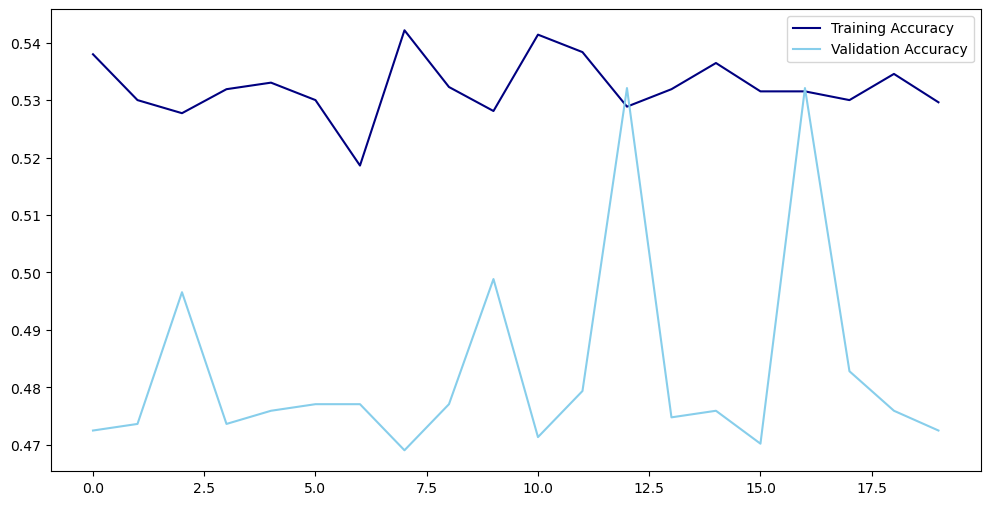

In [23]:
# How's our model?
plt.figure(figsize=(12, 6))
plt.plot(history.history['acc'], c='navy', label='Training Accuracy')
plt.plot(history.history['val_acc'], c='skyblue', label='Validation Accuracy')
plt.legend();

# Ok then... let's try something a little more predictable!
(The weather!)

We'll work with data recorded at the weather station at the Max Planck Institute for Biogeochemistry in Jena, Germany.

In [24]:
jena = pd.read_csv('./datasets/jena_2009_2010.csv')
jena.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


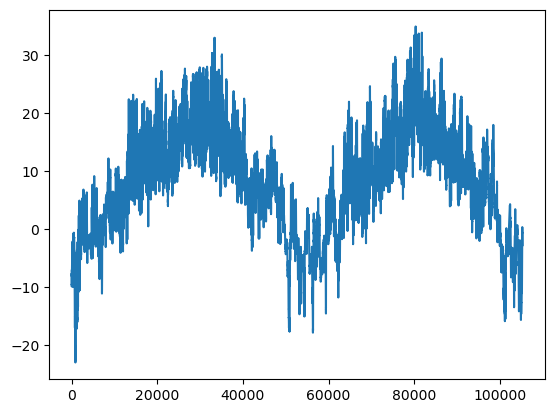

In [25]:
# Let's look at temperate in degrees Celsius.
plt.plot(jena['T (degC)']);
# What do we notice?

In [26]:
# We're going to take the future temperature 24 hours in the future
# as our target.
# 144 rows = 1440 min = 24 hours
jena['tomorrow_temp'] = jena['T (degC)'].shift(-144)
jena.dropna(inplace=True)
jena.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg),tomorrow_temp
0,2009-01-01 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3,-4.60
1,2009-01-01 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1,-4.67
2,2009-01-01 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6,-4.66
3,2009-01-01 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0,-4.55
4,2009-01-01 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3,-4.43


In [27]:
# Define X, y.
X = jena.drop(columns=['Date Time'])
y = jena['tomorrow_temp']

# Define training and testing sets, and scale.
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [28]:
X.head()

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg),tomorrow_temp
0,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3,-4.60
1,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1,-4.67
2,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6,-4.66
3,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0,-4.55
4,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3,-4.43


In [29]:
y.head()

0   -4.60
1   -4.67
2   -4.66
3   -4.55
4   -4.43
Name: tomorrow_temp, dtype: float64

In [30]:
# This dataset is big, so I'm going to take Francois Chollet's
# advice on this:
seq_len = 120
batch_size = 256

# What do you think this controls?
sampling_rate = 6
# Take only one observation per hour.
# 1 observation every 10 minutes * sampling 1 of every 6 observation --> 1 per hour.

# What do you think are the advantages of changing the sampling rate? The disadvantages?

train_gen = timeseries_dataset_from_array(
    X_train_sc,
    y_train,
    sequence_length=seq_len,
    sampling_rate=sampling_rate,
    batch_size=batch_size
)

val_gen = timeseries_dataset_from_array(
    X_test_sc,
    y_test,
    sequence_length=seq_len,
    sampling_rate=sampling_rate,
    batch_size=batch_size
)

In [31]:
# We'll see some success with only a moderate model here
# Two LSTMs directly into a dense output.
model = Sequential()

# Add input layer.
model.add(Input(shape=(seq_len, X_train.shape[1])))

# Add LSTM layer with 32 nodes.
model.add(LSTM(32, return_sequences=True))

# Add another LSTM layer with 32 nodes.
model.add(LSTM(32))

# Add output layer. (Nodes? Activation?)
model.add(Dense(1))

In [32]:
# Compile.
model.compile(loss='mse',
              optimizer='rmsprop',
              metrics=['mae'])

In [34]:
# Fit and save history. 
# This will take a while to run — maybe 10 minutes.
history_temp = model.fit(train_gen,
                         validation_data=val_gen,
                         epochs=10)

Epoch 1/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 53s 164ms/step - loss: 54.5593 - mae: 5.7362 - val_loss: 47.2440 - val_mae: 5.2687
Epoch 2/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 59s 193ms/step - loss: 30.2708 - mae: 4.1442 - val_loss: 35.2583 - val_mae: 4.5050
Epoch 3/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 54s 175ms/step - loss: 23.9449 - mae: 3.7189 - val_loss: 25.8856 - val_mae: 3.8725
Epoch 4/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 55s 178ms/step - loss: 20.0822 - mae: 3.4196 - val_loss: 22.7321 - val_mae: 3.6745
Epoch 5/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 51s 168ms/step - loss: 18.4077 - mae: 3.2712 - val_loss: 19.6967 - val_mae: 3.4396
Epoch 6/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 54s 177ms/step - loss: 15.8819 - mae: 2.9991 - val_loss: 19.0982 - val_mae: 3.4552
Epoch 7/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 52s 171ms/step - loss: 14.3237 - mae: 2.8126 - val_loss: 15.6564 - val_mae: 2.9790
Epoch 8/10
306/306 ━━━━━━━━━━━━━━━━━━━━ 53s 175ms/step - loss: 13.7437 - mae: 2.7439 - val_loss: 15.2792 - val_mae: 2.8993
Epoch 9/10
306/3

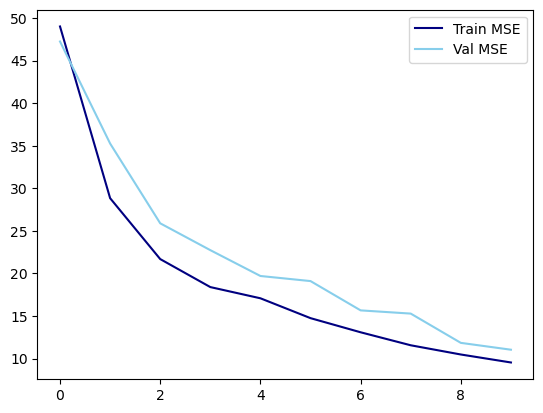

In [35]:
# Plot our MSE chart - what do we see?
plt.plot(history_temp.history['loss'], c='navy', label='Train MSE')
plt.plot(history_temp.history['val_loss'], c='skyblue', label='Val MSE')
plt.legend();

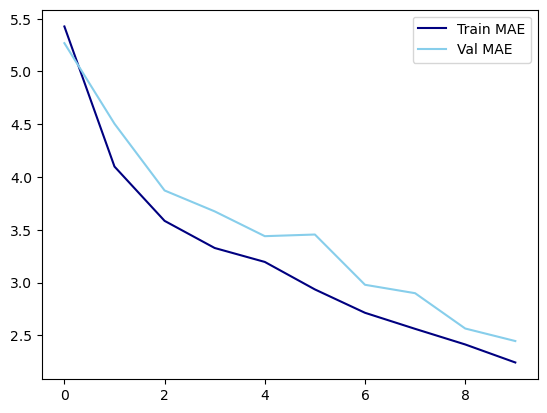

In [36]:
# Plot our MSE chart - what do we see?
plt.plot(history_temp.history['mae'], c='navy', label='Train MAE')
plt.plot(history_temp.history['val_mae'], c='skyblue', label='Val MAE')
plt.legend();